# Benchmarking model behaviors with their performances

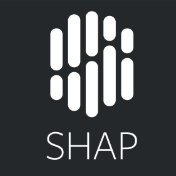

<i> 

<br>
<br>




---

## Code

<i>

We start by making a dictionary full of models we want to benchmark

In this case, I'm benchmarking:

* `XGBoost`
* `RandomForestRegressor`
* `LinearRegressor`

We run all the models in a loop and retrieve both the performance metrics and the shapley feature values.


In [18]:
# Imports
import shap
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

# Load into a single DataFrame
df = fetch_california_housing(as_frame=True).frame
df = df.rename(columns={"MedHouseVal": "target"})

# Split features / target from the dataset
X = df.drop(columns="target")
y = df["target"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# PLACE MODELS IN HERE! It will train all of these models in 
# a loop and spit out the metrics all at once in a dataframe.
models = {
    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=6,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ),

    "Linear Regression": LinearRegression()
}

# Train, metrics, and put them into the results dictionary.
results = {}

for name, model in models.items():

    model.fit(X_train, y_train)
    
    y_pred = model.predict(X_test)

    results[name] = {
        "R2": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred)
    }

# Display results and round to four decimal places for sanity purposes.
performance_df = pd.DataFrame(results)
performance_df.round(4)

# Alright! And now you have the performance metrics for benchmarking. 

,XGBoost,Random Forest,Linear Regression
R2,0.8052,0.6793,0.5758
RMSE,0.5052,0.6483,0.7456
MAE,0.3388,0.4608,0.5332


<i> Next up, we create create the Shapley values for each mean. Because the Shapley values differ for each row, we'll aggregate the Shapley values by the mean.

In [ ]:
shap_values_dict = {}

# This will create a `shap` object, make the Shapley
# values for you, and place it in the dictionary above.
for name, model in models.items():

    # In this case, we're going to use `shap.Explainer()`, it
    # automatically selects the appropriate explainer for you
    # NOTE: If you're using a not-so-popular model, this might break!
    explainer = shap.Explainer(model, X_train)
    shap_values = explainer(X_test)

    # Place it in the dictionary above.
    shap_values_dict[name] = shap_values

 96%|=================== | 3976/4128 [00:12<00:00]       

<i>

And finally,

now we have a dictionary full of shapley aggregates for each mean...

We turn it into a dataframe and combine it with the performance benchmarks

In [ ]:
# We're going to use the same approach here,
# We take each feature's Shapley values and aggregate it by it's average.
# Then place it into the importance dictionary.
importance_dict = {}

for name, shap_values in shap_values_dict.items():
    # Take the mean Shapley value of each feature and place it into the 
    # importance dictionary. You could alternatively aggregate by other
    # statistics (like .var would be pretty interesting!)
    importance_dict[name] = np.abs(shap_values.values).mean(axis=0)

# Turn it into a dataframe.
importance_df = pd.DataFrame(
    importance_dict,
    index=X_test.columns
)

# Now we have the importance and the performance metrics
# But we'll also combine them into a single dataframe as well.
benchmark_df = pd.concat([importance_df, performance_df])

# Show and round each value by four decimal places.
benchmark_df.round(4)

# Lets extract the index so we can use it for plotting
importance_df = importance_df.reset_index()
importance_df.rename(columns={"index": "Feature"}, inplace=True)

performance_df = performance_df.reset_index()
performance_df.rename(columns={"index": "Metrics"}, inplace=True)

benchmark_df = benchmark_df.reset_index()
benchmark_df.rename(columns={"index": "Feature/Metrics"}, inplace=True)

# shapley_df.round(4)
# performance_df.round(4)

<i> Now we've made three useful dataframes that shows us our model metrics and Shapley values for benchmarking

|DataFrame|Description|
|---|---|
|<b style="color:#3BEB28; background-color:black;"> importance_df| Aggregated Shapley values|
|<b style="color:#EB2828; background-color:black;"> performance_df| Model Performance metrics|
|<b style="color:#E128EB; background-color:black;"> benchmark_df| Aggregated Shapley values + Model Performance metrics |



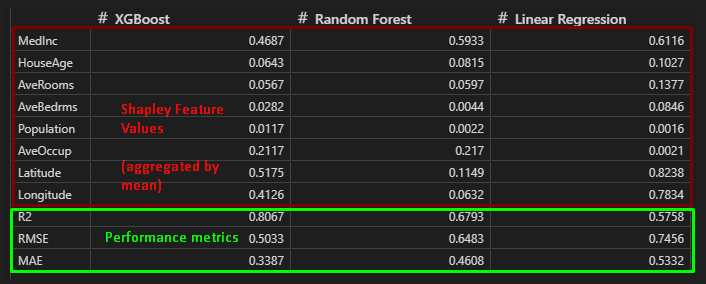

---

## <i> Visuals

Now let's make some visuals.


### <i> Shapley value benchmarking

This will help you determine how each model values specific features.

In [ ]:
# For this visual, let's use melt to extract the scores into it's own feature
# That way we can use it for visualization
importance_long = importance_df.melt(
    id_vars="Feature",
    var_name="Model",
    value_name="Score"
)
importance_long


,Feature,Model,Score
0,MedInc,XGBoost,0.467839
1,HouseAge,XGBoost,0.066483
2,AveRooms,XGBoost,0.052597
3,AveBedrms,XGBoost,0.027759
4,Population,XGBoost,0.012435
5,AveOccup,XGBoost,0.212541
6,Latitude,XGBoost,0.509881
7,Longitude,XGBoost,0.411299
8,MedInc,Random Forest,0.593296
9,HouseAge,Random Forest,0.081561


Text(0.5, 1.0, 'Mean aggregated shapley values by feature')

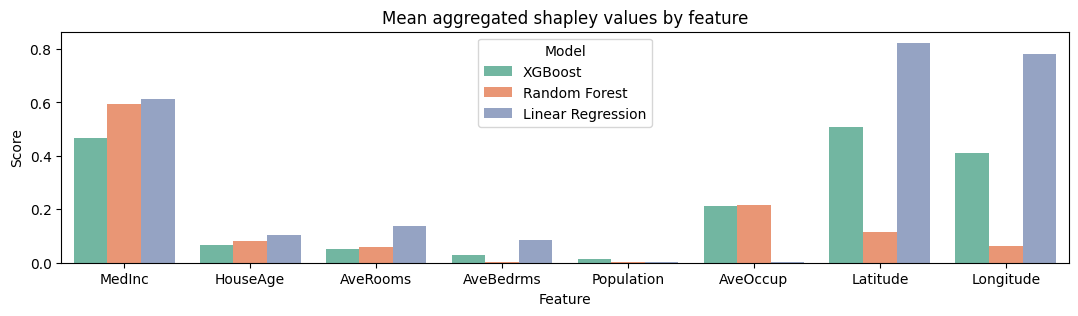

In [22]:
# Now, let's create a bar plot

# We make the plot plot wider and bigger
plt.figure(figsize=(13,3))

sns.barplot(importance_long, x="Feature", y="Score", hue="Model", palette="Set2")
plt.title("Mean aggregated shapley values by feature")

---

### <i> Model Performance Benchmarking 

We can also use the same approach for standard performance metrics benchmarking

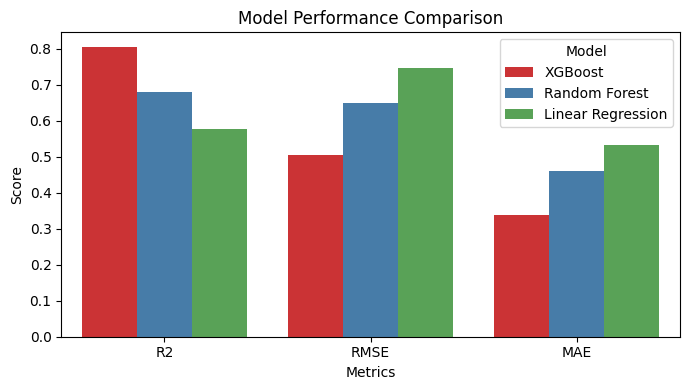

In [23]:
# We make the plot size a little bit wider shorter
plt.figure(figsize=(7,4))

# Let's melt/un-pivot the values so we have a score column.
performance_long = performance_df.melt(
    id_vars="Metrics",
    var_name="Model",
    value_name="Score"
)

# And 
sns.barplot(data=performance_long,x="Metrics",y="Score",hue="Model", palette="Set1")

plt.title("Model Performance Comparison")
plt.tight_layout()
plt.show()


<i>

These approaches above make for a quick, rapid-fire way to test all sorts of models in quick-succession. It's meant to save us time! 